In [1]:
import textwrap
import matplotlib.pyplot as plt


def make_description_layout(connection_title):
    # Presentation only: three graphs above three description boxes.
    fig = plt.figure(figsize=(18, 8), facecolor='white')
    grid = fig.add_gridspec(
        2, 3, height_ratios=[3.6, 1.65],
        left=0.055, right=0.955, bottom=0.05, top=0.86,
        wspace=0.70, hspace=0.40,
    )
    axes = tuple(fig.add_subplot(grid[0, col]) for col in range(3))
    description_axes = [fig.add_subplot(grid[1, col]) for col in range(3)]
    titles = ['Graph 1: Network spikes', 'Graph 2: Weight and spikes',
              'Graph 3: Initial matrix']
    for axis, title in zip(axes, titles):
        axis.set_title(title, fontsize=12, pad=14)
    fig.suptitle(connection_title, fontsize=17, fontweight='bold', y=0.97)
    fig.text(0.5, 0.92, '10 cells | 700 ms | HiFrac = 0.5',
             ha='center', fontsize=11)
    fill_description_boxes(description_axes, ['', '', ''])
    return fig, axes, description_axes


def fill_description_boxes(description_axes, descriptions):
    # Rerunning this replaces only the text; graph data are untouched.
    if len(descriptions) != 3:
        raise ValueError('Provide one description for each of the three graphs.')
    for number, (axis, description) in enumerate(zip(description_axes, descriptions), 1):
        axis.clear()
        axis.set_xlim(0, 1)
        axis.set_ylim(0, 1)
        axis.set_xticks([])
        axis.set_yticks([])
        axis.set_facecolor('#fafafa')
        for spine in axis.spines.values():
            spine.set_color('#b8b8b8')
            spine.set_linewidth(0.8)
        axis.text(0.04, 0.90, f'Graph {number} - My description',
                  transform=axis.transAxes, va='top', fontsize=11, fontweight='bold')
        body = description.strip() or 'Write your description here.'
        wrapped = '\n'.join(textwrap.fill(line, width=49) if line else ''
                            for line in body.splitlines())
        axis.text(0.04, 0.68, wrapped, transform=axis.transAxes,
                  va='top', ha='left', fontsize=10, linespacing=1.35,
                  color='#222222' if description.strip() else '#777777')


In [2]:
# big net with STDP (small scale example to trace a weight)

import numpy as np
import matplotlib.pyplot as plt
import math
import scipy  as sp     #.sparse import random_array
from scipy.sparse.csgraph import connected_components
import time

start_time = time.perf_counter()

fig, (ax1, ax2, ax3), description_axes = make_description_layout(
    'Cell 6 to cell 2'
)
ax4 = ax2.twinx()

rng = np.random.default_rng(12345)    # fixed random number generator

Tfin = 700
dt = 0.1
Nt = math.ceil(Tfin/dt)
tausyn = 1
td = 3
kappa = 8

N = 10   # number of cells

kappa_noise = 0.026
f_noise = 20

gleak = 0.02
Vrest = -38
Cm = rng.normal(3, 3*0.05, N)   #

if True:
    is_connected = False
    HiFrac = 0.5

    while not is_connected:  # Generate a fully connected sparse {0,1} weight matrix without self connections

        W = sp.sparse.random_array(    # Generate random array of values {1,2}
            (N, N), density= 0.25, random_state=rng,
            data_sampler = lambda size: rng.choice([1, 2], size=size, p=[1-HiFrac, HiFrac])
        ).tocsr()

        W.setdiag(0)   # remove self-connections
        W.eliminate_zeros()

        n_components, _ = connected_components(W, directed=True, connection='strong')
        is_connected = (n_components == 1)

    print("Successfully generated a fully connected synaptic weight matrix!")
    print("W.data[0:10] = ", W.data[0:10])
    print("W.indptr[0:10] = ", W.indptr[0:10])
    print("W.indices[0:10] = ", W.indices[0:10])

else:

    W = sp.sparse.load_npz('Wsp17As.npz')
    W.data += 1  # raise weights by 1 to take {1,2}


coo = W.tocoo()         # now capture the "connectivity"  of W
row_array = coo.row
col_to_data_slots = {}
col_to_pre_rows = {}

for col_idx in range(N):
    # Find every position in the matrix structure where the column matches
    slots = np.where(W.indices == col_idx)[0]
    col_to_data_slots[col_idx] = slots
    col_to_pre_rows[col_idx] = row_array[slots]

fW = W.toarray()    # for visualization purposes
im1 = ax3.imshow(fW, cmap='gray_r')
fig.colorbar(im1, ax=ax3)

W.data -= 1  # lower weights by 1 to take {0,1}

#Wbefore = W.toarray() # for comparison/visualization

aE = (2*tausyn-dt)/(2*tausyn+dt)
bE = 2*kappa/(2*tausyn+dt)/N
bEnoise = 2*kappa_noise/(2*tausyn+dt)

tref = 1
Vres = -67
Vthrrest = -40
Vthrspike = 0
tauthr = 5

aT = (tauthr - dt/2)/(tauthr + dt/2)
bT = dt*Vthrrest/(tauthr + dt/2)

gsyn = np.zeros(N)
g_noise = np.zeros(N)
V = rng.uniform(low = Vres, high = Vrest, size = N)
Vthr = Vthrspike*np.ones(N)
T = -10*np.ones(N)
ref = np.zeros(N)

a = 2*Cm/dt
b = 2*gleak*Vrest
c = a + gleak

next_noise = rng.exponential(1000.0 / f_noise, size=N)

tau_plus = 10
tau_R = 4
beta = 1.4
delta = 0.02 # 0.002   # from Thanos Manos ,Magteld Zeitler,Peter A. Tass

for j in range(1,Nt):

    t = j*dt

    gsyn = aE*gsyn  #  + bE*W@s

    s = T + td == t   #  spiked td milliseconds ago  ?

    if np.any(s):

        gsyn += bE*W@s

        old_spikes = np.where(s)[0]   # cells that spiked td milliseconds ago

        for ind in old_spikes:       # depress their postsynaptic weights

            data_slots = col_to_data_slots[ind]
            post = col_to_pre_rows[ind]
            Delta = T[post] - t    #  t_post - (t_pre + 3)
            dW = (delta*beta/tau_R)*np.exp(Delta/(tau_R*tau_plus))
            W.data[data_slots] -= dW
            W.data[data_slots] = np.clip(W.data[data_slots], 0.0, 1.0)

    g_noise = aE*g_noise

    events = next_noise <= t

    if np.any(events):
        n_events = events.sum()
        g_noise[events] += bEnoise
        next_noise[events] += rng.exponential(1000.0 / f_noise, size=n_events)

    V = ( (a - (gleak + gsyn + g_noise))*V + b ) /  (c + gsyn + g_noise)

    #ax4.plot(t, V[2], 'r.')
    #ax4.plot(t, V[7], 'b.')

    Vthr = aT*Vthr + bT

    ref = np.where( t-T < tref )
    V[ref] = Vres

    fsp = np.where(V > Vthr)[0]     # spiking cells

    T[fsp] = t
    V[fsp] = Vres
    Vthr[fsp] = Vthrspike

    for ind in fsp:   # potentiate presynaptic weights

        if t > Tfin - 1000:       # plot final second of spikes
            ax1.plot(t/1000, ind,'k.',markersize=6)
            if ind == 2:
                ax4.plot([t, t], [1, 1.01],'r')
                print(T)
            if ind == 6:
                ax4.plot([t, t], [1, 1.01],'b--')
                print(T)


        start, end = W.indptr[ind], W.indptr[ind+1]
        pre = W.indices[start:end]

        Delta = T[pre] + td - t   # (t_pre + td) - t_post
        Delta = np.where(Delta>0, -1e6, Delta)
        dW = delta*np.exp(Delta/tau_plus)
        if ind == 2:
            print("pre = ", pre)
            print("dW = ", dW)
        W.data[start:end] += dW   # *(1-W[ind, p])
        W.data[start:end] = np.clip(W.data[start:end], 0.0, 1.0)


    #if j % 1e4 == 0:
        #ax2.plot(t/1000, W.data.mean(), 'k.')
    ax2.plot(t, W.data[5], 'k.', markersize=4)
        #ax2.plot(t/1000, W[[Wrow[1]],[Wcol[1]]], 'r.')

    if j % (10*60*1e3) == 0:
        print(t/1000, W.data.mean())
    #    ax3.hist(W.data, 30, density=False, alpha = 1-j/Nt) #histtype = 'step') #, edgecolor='black')

ax1.set_xlabel('t (s)',fontsize=14)
ax1.set_ylabel('cell', color='k', fontsize=14)

ax2.set_xlabel('t (ms)',fontsize=14)
#ax2.set_ylabel('average weight', color='k', fontsize=14)
ax2.set_ylabel('$W_{6\\to 2}$ (black)', color='k', fontsize=14)
ax2.grid('on')
ax4.set_ylabel('spikes of cells 2 (red) and 6 (blue)', color='r', fontsize=14)

#ax3.grid('on')

#ax3.hist(W.data, 30, density=False, edgecolor='black')

end_time = time.perf_counter()
print(f"Elapsed time: {end_time - start_time:.6f} seconds")

#sp.sparse.save_npz('Wsp17AsAq.npz', W)

# Keep this completed figure for the description/display cell below.
figure_6_to_2 = fig
description_axes_6_to_2 = description_axes
plt.close(fig)  # Display both completed sets together in the final cell.


Successfully generated a fully connected synaptic weight matrix!
W.data[0:10] =  [1. 1. 1. 1. 2. 1. 2. 1. 1. 1.]
W.indptr[0:10] =  [ 0  2  5  7  8 10 12 14 16 19]
W.indices[0:10] =  [1 2 4 7 9 6 7 5 5 7]
[-10.  -10.  -10.  -10.  220.8 -10.  221.5 -10.   91.8 -10. ]
[-10.  -10.  247.2 -10.  220.8 -10.  221.5 -10.   91.8 -10. ]
pre =  [6 7]
dW =  [2.06624360e-03 1.82500587e-13]
[255.7 297.8 446.8 268.4 220.8 340.  221.5 271.4 343.1 300.8]
pre =  [6 7]
dW =  [4.43265227e-12 6.51318071e-10]
[255.7 518.7 446.8 268.4 549.2 340.  549.3 271.4 343.1 521.8]
[574.1 518.7 581.1 268.4 549.2 340.  549.3 577.1 343.1 521.8]
pre =  [6 7]
dW =  [0.0011227  0.01809675]
Elapsed time: 7.089882 seconds


In [3]:
# big net with STDP (small scale example to trace a weight)

import numpy as np
import matplotlib.pyplot as plt
import math
import scipy  as sp     #.sparse import random_array
from scipy.sparse.csgraph import connected_components
import time

start_time = time.perf_counter()

fig, (ax1, ax2, ax3), description_axes = make_description_layout(
    'Cell 7 to cell 2'
)
ax4 = ax2.twinx()

rng = np.random.default_rng(12345)    # fixed random number generator

Tfin = 700
dt = 0.1
Nt = math.ceil(Tfin/dt)
tausyn = 1
td = 3
kappa = 8

N = 10   # number of cells

kappa_noise = 0.026
f_noise = 20

gleak = 0.02
Vrest = -38
Cm = rng.normal(3, 3*0.05, N)   #

if True:
    is_connected = False
    HiFrac = 0.5

    while not is_connected:  # Generate a fully connected sparse {0,1} weight matrix without self connections

        W = sp.sparse.random_array(    # Generate random array of values {1,2}
            (N, N), density= 0.25, random_state=rng,
            data_sampler = lambda size: rng.choice([1, 2], size=size, p=[1-HiFrac, HiFrac])
        ).tocsr()

        W.setdiag(0)   # remove self-connections
        W.eliminate_zeros()

        n_components, _ = connected_components(W, directed=True, connection='strong')
        is_connected = (n_components == 1)

    print("Successfully generated a fully connected synaptic weight matrix!")
    print("W.data[0:10] = ", W.data[0:10])
    print("W.indptr[0:10] = ", W.indptr[0:10])
    print("W.indices[0:10] = ", W.indices[0:10])

else:

    W = sp.sparse.load_npz('Wsp17As.npz')
    W.data += 1  # raise weights by 1 to take {1,2}


coo = W.tocoo()         # now capture the "connectivity"  of W
row_array = coo.row
col_to_data_slots = {}
col_to_pre_rows = {}

for col_idx in range(N):
    # Find every position in the matrix structure where the column matches
    slots = np.where(W.indices == col_idx)[0]
    col_to_data_slots[col_idx] = slots
    col_to_pre_rows[col_idx] = row_array[slots]

fW = W.toarray()    # for visualization purposes
im1 = ax3.imshow(fW, cmap='gray_r')
fig.colorbar(im1, ax=ax3)

W.data -= 1  # lower weights by 1 to take {0,1}

#Wbefore = W.toarray() # for comparison/visualization

aE = (2*tausyn-dt)/(2*tausyn+dt)
bE = 2*kappa/(2*tausyn+dt)/N
bEnoise = 2*kappa_noise/(2*tausyn+dt)

tref = 1
Vres = -67
Vthrrest = -40
Vthrspike = 0
tauthr = 5

aT = (tauthr - dt/2)/(tauthr + dt/2)
bT = dt*Vthrrest/(tauthr + dt/2)

gsyn = np.zeros(N)
g_noise = np.zeros(N)
V = rng.uniform(low = Vres, high = Vrest, size = N)
Vthr = Vthrspike*np.ones(N)
T = -10*np.ones(N)
ref = np.zeros(N)

a = 2*Cm/dt
b = 2*gleak*Vrest
c = a + gleak

next_noise = rng.exponential(1000.0 / f_noise, size=N)

tau_plus = 10
tau_R = 4
beta = 1.4
delta = 0.02 # 0.002   # from Thanos Manos ,Magteld Zeitler,Peter A. Tass

for j in range(1,Nt):

    t = j*dt

    gsyn = aE*gsyn  #  + bE*W@s

    s = T + td == t   #  spiked td milliseconds ago  ?

    if np.any(s):

        gsyn += bE*W@s

        old_spikes = np.where(s)[0]   # cells that spiked td milliseconds ago

        for ind in old_spikes:       # depress their postsynaptic weights

            data_slots = col_to_data_slots[ind]
            post = col_to_pre_rows[ind]
            Delta = T[post] - t    #  t_post - (t_pre + 3)
            dW = (delta*beta/tau_R)*np.exp(Delta/(tau_R*tau_plus))
            W.data[data_slots] -= dW
            W.data[data_slots] = np.clip(W.data[data_slots], 0.0, 1.0)

    g_noise = aE*g_noise

    events = next_noise <= t

    if np.any(events):
        n_events = events.sum()
        g_noise[events] += bEnoise
        next_noise[events] += rng.exponential(1000.0 / f_noise, size=n_events)

    V = ( (a - (gleak + gsyn + g_noise))*V + b ) /  (c + gsyn + g_noise)

    #ax4.plot(t, V[2], 'r.')
    #ax4.plot(t, V[7], 'b.')

    Vthr = aT*Vthr + bT

    ref = np.where( t-T < tref )
    V[ref] = Vres

    fsp = np.where(V > Vthr)[0]     # spiking cells

    T[fsp] = t
    V[fsp] = Vres
    Vthr[fsp] = Vthrspike

    for ind in fsp:   # potentiate presynaptic weights

        if t > Tfin - 1000:       # plot final second of spikes
            ax1.plot(t/1000, ind,'k.',markersize=6)
            if ind == 2:
                ax4.plot([t, t], [1, 1.01],'r')
                print(T)
            if ind == 7:
                ax4.plot([t, t], [1, 1.01],'b--')
                print(T)


        start, end = W.indptr[ind], W.indptr[ind+1]
        pre = W.indices[start:end]

        Delta = T[pre] + td - t   # (t_pre + td) - t_post
        Delta = np.where(Delta>0, -1e6, Delta)
        dW = delta*np.exp(Delta/tau_plus)
        if ind == 2:
            print("pre = ", pre)
            print("dW = ", dW)
        W.data[start:end] += dW   # *(1-W[ind, p])
        W.data[start:end] = np.clip(W.data[start:end], 0.0, 1.0)


    #if j % 1e4 == 0:
        #ax2.plot(t/1000, W.data.mean(), 'k.')
    ax2.plot(t, W.data[6], 'k.', markersize=4)
        #ax2.plot(t/1000, W[[Wrow[1]],[Wcol[1]]], 'r.')

    if j % (10*60*1e3) == 0:
        print(t/1000, W.data.mean())
    #    ax3.hist(W.data, 30, density=False, alpha = 1-j/Nt) #histtype = 'step') #, edgecolor='black')

ax1.set_xlabel('t (s)',fontsize=14)
ax1.set_ylabel('cell', color='k', fontsize=14)

ax2.set_xlabel('t (ms)',fontsize=14)
#ax2.set_ylabel('average weight', color='k', fontsize=14)
ax2.set_ylabel('$W_{7\\to 2}$ (black)', color='k', fontsize=14)
ax2.grid('on')
ax4.set_ylabel('spikes of cells 2 (red) and 7 (blue)', color='r', fontsize=14)

#ax3.grid('on')

#ax3.hist(W.data, 30, density=False, edgecolor='black')

end_time = time.perf_counter()
print(f"Elapsed time: {end_time - start_time:.6f} seconds")

#sp.sparse.save_npz('Wsp17AsAq.npz', W)

# Keep this completed figure for the description/display cell below.
figure_7_to_2 = fig
description_axes_7_to_2 = description_axes
plt.close(fig)  # Display both completed sets together in the final cell.


Successfully generated a fully connected synaptic weight matrix!
W.data[0:10] =  [1. 1. 1. 1. 2. 1. 2. 1. 1. 1.]
W.indptr[0:10] =  [ 0  2  5  7  8 10 12 14 16 19]
W.indices[0:10] =  [1 2 4 7 9 6 7 5 5 7]
[-10.  -10.  247.2 -10.  220.8 -10.  221.5 -10.   91.8 -10. ]
pre =  [6 7]
dW =  [2.06624360e-03 1.82500587e-13]
[255.7 -10.  247.2 268.4 220.8 -10.  221.5 271.4  91.8 -10. ]
[255.7 297.8 446.8 268.4 220.8 340.  221.5 271.4 343.1 300.8]
pre =  [6 7]
dW =  [4.43265227e-12 6.51318071e-10]
[574.1 518.7 446.8 268.4 549.2 340.  549.3 577.1 343.1 521.8]
[574.1 518.7 581.1 268.4 549.2 340.  549.3 577.1 343.1 521.8]
pre =  [6 7]
dW =  [0.0011227  0.01809675]
Elapsed time: 7.608712 seconds


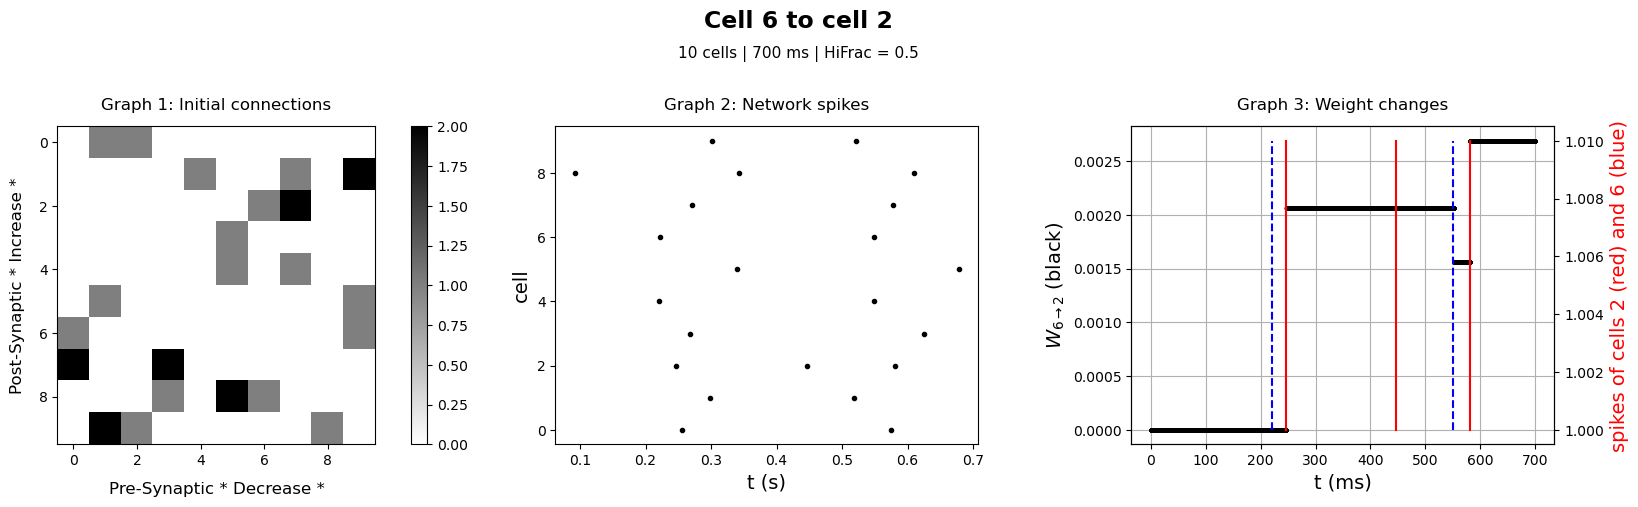

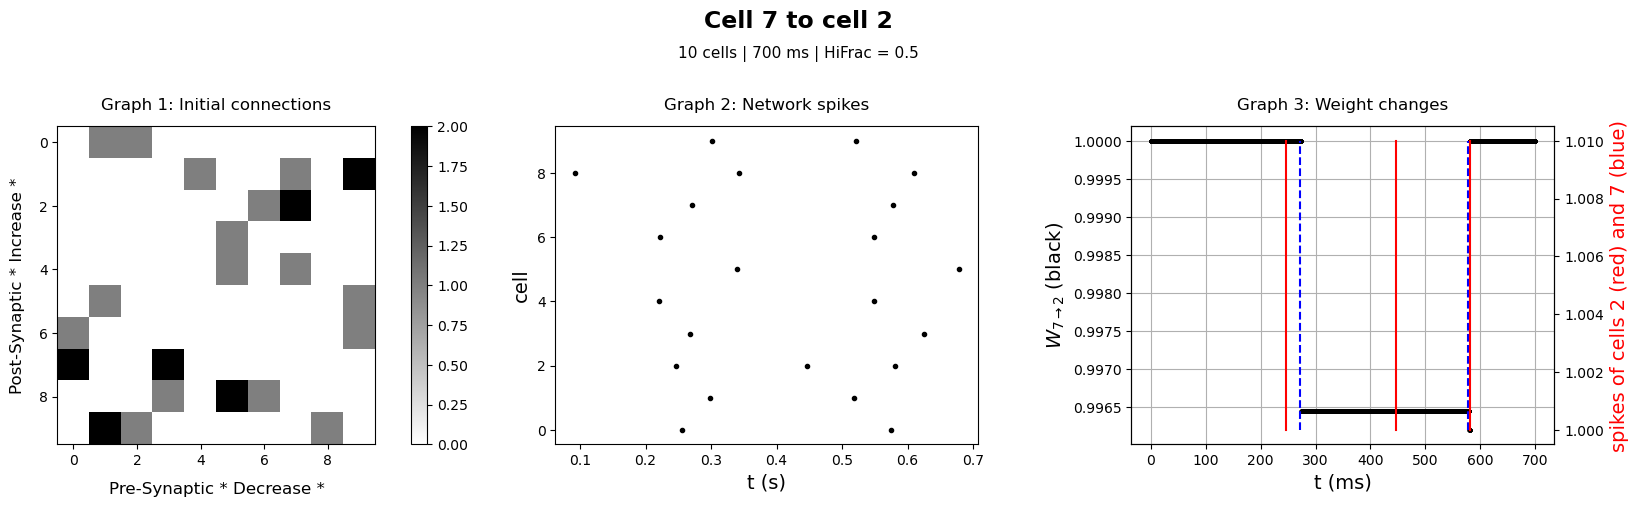

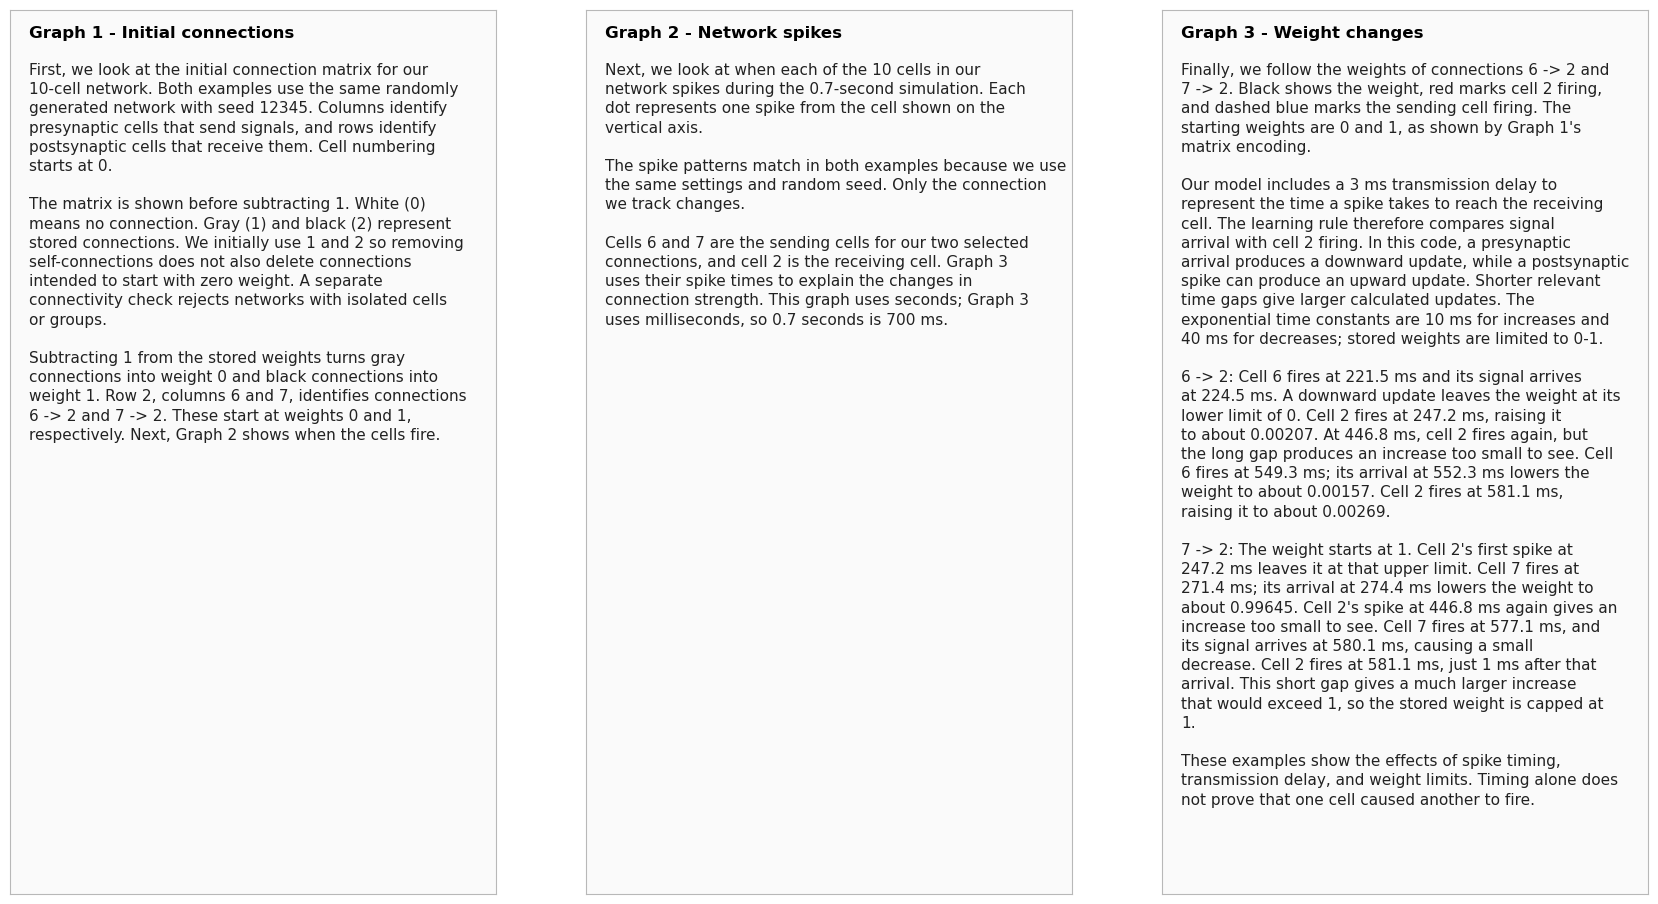

In [4]:
import textwrap
import matplotlib.pyplot as plt

descriptions = [
    # Graph 1: Initial connections
    """First, we look at the initial connection matrix for our 10-cell network. Both examples use the same randomly generated network with seed 12345. Columns identify presynaptic cells that send signals, and rows identify postsynaptic cells that receive them. Cell numbering starts at 0.

The matrix is shown before subtracting 1. White (0) means no connection. Gray (1) and black (2) represent stored connections. We initially use 1 and 2 so removing self-connections does not also delete connections intended to start with zero weight. A separate connectivity check rejects networks with isolated cells or groups.

Subtracting 1 from the stored weights turns gray connections into weight 0 and black connections into weight 1. Row 2, columns 6 and 7, identifies connections 6 -> 2 and 7 -> 2. These start at weights 0 and 1, respectively. Next, Graph 2 shows when the cells fire.""",

    # Graph 2: Network spikes
    """Next, we look at when each of the 10 cells in our network spikes during the 0.7-second simulation. Each dot represents one spike from the cell shown on the vertical axis.

The spike patterns match in both examples because we use the same settings and random seed. Only the connection we track changes.

Cells 6 and 7 are the sending cells for our two selected connections, and cell 2 is the receiving cell. Graph 3 uses their spike times to explain the changes in connection strength. This graph uses seconds; Graph 3 uses milliseconds, so 0.7 seconds is 700 ms.""",

    # Graph 3: Weight changes, including the reason for the 3 ms delay
    """Finally, we follow the weights of connections 6 -> 2 and 7 -> 2. Black shows the weight, red marks cell 2 firing, and dashed blue marks the sending cell firing. The starting weights are 0 and 1, as shown by Graph 1's matrix encoding.

Our model includes a 3 ms transmission delay to represent the time a spike takes to reach the receiving cell. The learning rule therefore compares signal arrival with cell 2 firing. In this code, a presynaptic arrival produces a downward update, while a postsynaptic spike can produce an upward update. Shorter relevant time gaps give larger calculated updates. The exponential time constants are 10 ms for increases and 40 ms for decreases; stored weights are limited to 0-1.

6 -> 2: Cell 6 fires at 221.5 ms and its signal arrives at 224.5 ms. A downward update leaves the weight at its lower limit of 0. Cell 2 fires at 247.2 ms, raising it to about 0.00207. At 446.8 ms, cell 2 fires again, but the long gap produces an increase too small to see. Cell 6 fires at 549.3 ms; its arrival at 552.3 ms lowers the weight to about 0.00157. Cell 2 fires at 581.1 ms, raising it to about 0.00269.

7 -> 2: The weight starts at 1. Cell 2's first spike at 247.2 ms leaves it at that upper limit. Cell 7 fires at 271.4 ms; its arrival at 274.4 ms lowers the weight to about 0.99645. Cell 2's spike at 446.8 ms again gives an increase too small to see. Cell 7 fires at 577.1 ms, and its signal arrives at 580.1 ms, causing a small decrease. Cell 2 fires at 581.1 ms, just 1 ms after that arrival. This short gap gives a much larger increase that would exceed 1, so the stored weight is capped at 1.

These examples show the effects of spike timing, transmission delay, and weight limits. Timing alone does not prove that one cell caused another to fire.""",
]


def order_graphs_for_reading(fig):
    # Find the actual graph axes, including the second scale and color bar.
    # This works after the earlier one-row description/spacing edits too.
    matrix_axis = next(axis for axis in fig.axes if axis.images)
    matrix_axis.set_xlabel("Pre-Synaptic * Decrease *", fontsize=12, labelpad=10)
    matrix_axis.set_ylabel("Post-Synaptic * Increase *", fontsize=12, labelpad=10)
    raster_axis = next(axis for axis in fig.axes if axis.get_ylabel() == 'cell')
    weight_axis = next(axis for axis in fig.axes
                       if axis.get_ylabel().startswith('$W_'))
    spike_axis = next(axis for axis in fig.axes
                      if axis.get_ylabel().startswith('spikes of cells'))
    colorbar_axis = matrix_axis.images[0].colorbar.ax

    graph_axes = [matrix_axis, raster_axis, weight_axis, spike_axis, colorbar_axis]
    for axis in list(fig.axes):
        if axis not in graph_axes:
            axis.remove()  # Remove the old description boxes only.

    fig.set_size_inches(18, 5.3)
    heading = fig.suptitle(fig.get_suptitle(), fontsize=17, fontweight='bold', y=0.98)
    for text in fig.texts:
        if text is not heading:
            text.set_position((0.5, 0.89))
            text.set_ha('center')

    # Place graphs in their new order while preserving all plotted data.
    matrix_axis.set_position([0.045, 0.16, 0.22, 0.60])
    colorbar_axis.set_position([0.285, 0.16, 0.013, 0.60])
    raster_axis.set_position([0.365, 0.16, 0.235, 0.60])
    weight_axis.set_position([0.685, 0.16, 0.235, 0.60])
    spike_axis.set_position(weight_axis.get_position())

    for axis, title in zip(
        [matrix_axis, raster_axis, weight_axis],
        ['Graph 1: Initial connections', 'Graph 2: Network spikes',
         'Graph 3: Weight changes'],
    ):
        axis.set_title(title, fontsize=12, pad=12)
    return fig


def make_shared_descriptions(texts):
    if len(texts) != 3:
        raise ValueError('Provide three descriptions in the new graph order.')
    wrapped_texts = []
    for text in texts:
        cleaned = textwrap.dedent(text).strip()
        wrapped_texts.append('\n'.join(
            textwrap.fill(line.strip(), width=56) if line.strip() else ''
            for line in cleaned.splitlines()
        ))

    # Make the boxes tall enough for the longest description.
    font_size = 11
    line_spacing = 1.35
    max_lines = max(text.count('\n') + 1 for text in wrapped_texts)
    height = max(2.5, (0.80 + max_lines * font_size * line_spacing / 72) / 0.94)
    notes_fig = plt.figure(figsize=(18, height), facecolor='white')
    box_height_inches = height * 0.94
    titles = ['Graph 1 - Initial connections', 'Graph 2 - Network spikes',
              'Graph 3 - Weight changes']
    for left, title, body in zip([0.045, 0.365, 0.685], titles, wrapped_texts):
        axis = notes_fig.add_axes([left, 0.03, 0.27, 0.94])
        axis.set_xticks([])
        axis.set_yticks([])
        axis.set_facecolor('#fafafa')
        for spine in axis.spines.values():
            spine.set_color('#b8b8b8')
            spine.set_linewidth(0.8)
        axis.text(0.04, 1 - 0.16 / box_height_inches, title,
                  transform=axis.transAxes, ha='left', va='top',
                  fontsize=12, fontweight='bold')
        axis.text(0.04, 1 - 0.53 / box_height_inches, body,
                  transform=axis.transAxes, ha='left', va='top',
                  fontsize=font_size, linespacing=line_spacing, color='#222222')
    plt.close(notes_fig)  # Avoid an extra automatic display in Jupyter.
    return notes_fig


order_graphs_for_reading(figure_6_to_2)
order_graphs_for_reading(figure_7_to_2)
description_figure = make_shared_descriptions(descriptions)

display(figure_6_to_2)
display(figure_7_to_2)
display(description_figure)
